# Chapitre 9 - Exercices 9.1 à 9.6

Ce notebook traite six exercices sur les goulots, les métriques et la compression :

- **9.1** : classer des opérations sur le roofline d'un H100 et de notre RTX ;
- **9.2** : calculer MBU et MFU, de l'exemple papier à la mesure sur GPU ;
- **9.3** : percentiles, SLO et goodput d'un serveur simulé selon la charge ;
- **9.4** : coût par million de tokens, auto-hébergement contre API ;
- **9.5** : dimensionner un service pour Llama 3-70B ;
- **9.6** : quantification par groupes, symétrique ou asymétrique, et vitesse attendue.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from aie import llm
from aie import ch09_inference as inf
from aie.ch02_modeles import KNOWN_CONFIGS, count_params_config, kv_cache_bytes, plain_log_axis
from aie.diagrams import Diagram
from aie.plotting import (set_style, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, LIGHT,
                          annotate_bars, subtitle, finish)

set_style()
warnings.filterwarnings("ignore")
llm.seed_everything(0)
rng = np.random.default_rng(0)
pd.set_option("display.precision", 3)
H100, RTX = inf.ACCELERATORS["H100 SXM"], inf.ACCELERATORS["RTX 5070 Laptop"]

## Exercice 9.1 : Classer des opérations sur le roofline

**Énoncé.** Pour chacune des opérations suivantes, en bf16, calculer l'intensité
arithmétique et dire si elle est limitée par le calcul ou par la bande passante sur un
H100 SXM (989 TFLOP/s, 3,35 To/s) et sur la RTX 5070 Laptop (environ 57 TFLOP/s, 384 Go/s).
Donner le temps minimal de chacune sur H100.

1. Addition résiduelle de deux tenseurs $(4096 \times 8192)$ ;
2. projection $W_Q$ ($8192 \times 8192$) d'un token en decode ;
3. la même projection appliquée à un lot de 64 tokens en decode ;
4. la même projection pendant le prefill d'un prompt de 4096 tokens ;
5. les scores d'attention $q K^\top$ d'**un** token en decode contre un cache de 8192
   clés de dimension 128 (une tête).

**Rappels.** Intensité $I = \text{FLOPs}/\text{octets}$ ; point d'équilibre
$I^* = \pi/\beta$ ; temps minimal $\max(\text{FLOPs}/\pi, \text{octets}/\beta)$ (cours 1,
section 2, et section *Computational bottlenecks* du livre). Un produit $(m \times k)(k \times n)$
fait $2mkn$ FLOPs et déplace au moins $2(mk + kn + mn)$ octets en bf16.

**Solution.**

1. Addition : $n = 4096 \cdot 8192 \approx 3{,}4 \cdot 10^7$ additions, $3 \times 2n$ octets
   (deux lectures, une écriture) : $I = 1/6$. Très limité par la mémoire.
2. Decode, 1 token : $(1 \times 8192)(8192 \times 8192)$, $I \approx 1$ : mémoire.
3. 64 tokens : $I \approx \frac{64 \cdot 8192^2}{8192^2 + 2 \cdot 64 \cdot 8192} \approx 63$ :
   toujours sous les deux points d'équilibre (environ 150 et 295), donc mémoire, mais 63 fois
   plus de travail pour (presque) le même temps.
4. Prefill de 4096 tokens : $I = \frac{4096 \cdot 8192^2}{8192^2 + 2 \cdot 4096 \cdot 8192}
   = \frac{4096 \cdot 8192}{8192 + 8192} = 2048$ : limité par le calcul.
5. Scores en decode : $(1 \times 128)(128 \times 8192)$ : on lit tout le cache de clés
   ($2 \cdot 128 \cdot 8192$ octets) pour $2 \cdot 128 \cdot 8192$ FLOPs : $I \approx 1$.
   L'attention en decode est, elle aussi, limitée par la mémoire, et son coût croît avec
   le contexte. $\blacksquare$

In [2]:
ops = {"1. addition résiduelle": (4096 * 8192, 3 * 2 * 4096 * 8192),
       "2. W_Q, decode 1 token": (inf.matmul_flops(1, 8192, 8192), inf.matmul_bytes(1, 8192, 8192)),
       "3. W_Q, decode 64 tokens": (inf.matmul_flops(64, 8192, 8192), inf.matmul_bytes(64, 8192, 8192)),
       "4. W_Q, prefill 4096": (inf.matmul_flops(4096, 8192, 8192), inf.matmul_bytes(4096, 8192, 8192)),
       "5. q K^T, cache 8192": (inf.matmul_flops(1, 128, 8192), inf.matmul_bytes(1, 128, 8192))}
rows = []
for name, (f, b) in ops.items():
    I = f / b
    rows.append({"opération": name, "intensité": I,
                 "H100": inf.bound_kind(I, H100["flops"]["bf16"], H100["bw"]),
                 "RTX": inf.bound_kind(I, RTX["flops"]["bf16"], RTX["bw"]),
                 "temps min. H100 (µs)": inf.time_lower_bound(f, b, H100["flops"]["bf16"], H100["bw"]) * 1e6})
res91 = pd.DataFrame(rows)
display(res91.style.format({"intensité": "{:.2f}", "temps min. H100 (µs)": "{:.2f}"}).hide(axis="index"))

opération,intensité,H100,RTX,temps min. H100 (µs)
1. addition résiduelle,0.17,mémoire,mémoire,60.10
"2. W_Q, decode 1 token",1.00,mémoire,mémoire,40.07
"3. W_Q, decode 64 tokens",63.02,mémoire,mémoire,40.69
"4. W_Q, prefill 4096",2048.00,calcul,calcul,555.87
"5. q K^T, cache 8192",0.99,mémoire,mémoire,0.63


**Vérification graphique.**

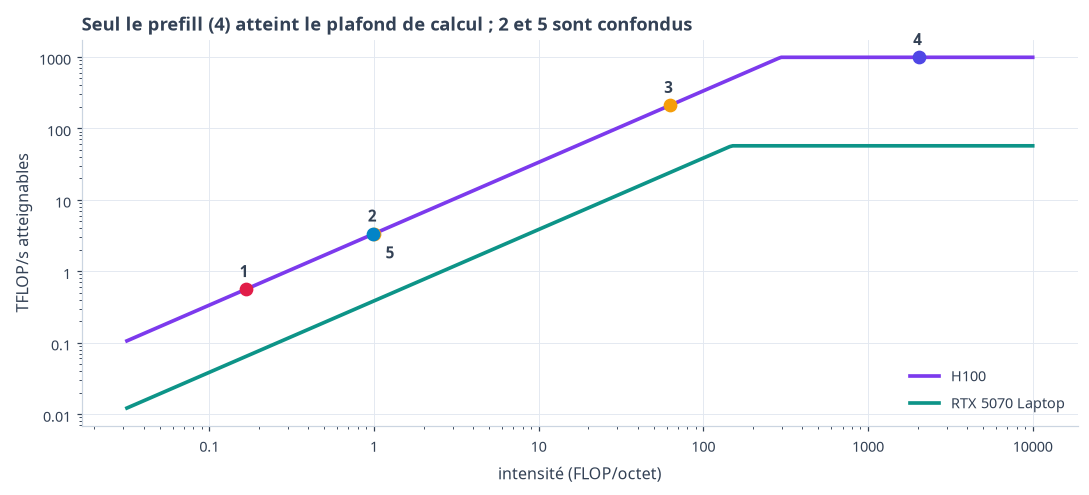

In [3]:
I_ = np.logspace(-1.5, 4, 300)
fig, ax = plt.subplots(figsize=(10, 4.6))
for name, a, c in [("H100", H100, VIOLET), ("RTX 5070 Laptop", RTX, TEAL)]:
    ax.plot(I_, inf.roofline(I_, a["flops"]["bf16"], a["bw"]) / 1e12, color=c, lw=2.4, label=name)
for k, r in res91.iterrows():
    y = float(inf.roofline(r["intensité"], H100["flops"]["bf16"], H100["bw"])) / 1e12
    ax.plot(r["intensité"], y, "o", color=[ROSE, AMBER, AMBER, INDIGO, SKY][k], ms=8)
    ax.annotate(r["opération"].split(". ")[0], (r["intensité"], y), textcoords="offset points",
                xytext=(8, -16) if k == 4 else (-4, 8), fontsize=10, fontweight="bold")
ax.set_xscale("log"); ax.set_yscale("log"); plain_log_axis(ax, "x"); plain_log_axis(ax, "y")
ax.set_xlabel("intensité (FLOP/octet)"); ax.set_ylabel("TFLOP/s atteignables")
ax.set_title("Seul le prefill (4) atteint le plafond de calcul ; 2 et 5 sont confondus"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

> **À retenir.** En inférence, presque tout est limité par la mémoire sauf les grands
> produits du prefill : opérations élément par élément ($I < 1$), decode ($I \approx B$),
> attention en decode ($I \approx 1$ quel que soit le lot, car chaque séquence a son cache).

## Exercice 9.2 : MBU et MFU, du papier à la mesure

**Énoncé.**

1. Llama 2-70B en fp16 est servi en parallélisme de tenseur sur 2 H100 (3,35 To/s chacun) ;
   chaque utilisateur reçoit 25 tokens/s, avec un lot de 1. Quelle est la MBU ? Que
   devient-elle avec un lot de 16 si le TPOT ne change pas ?
2. Même question pour la MFU (989 TFLOP/s par GPU).
3. Mini-lab : mesurer la MBU de Qwen2.5-0.5B en decode sur notre GPU pour plusieurs tailles
   de lot et de contexte, **en comptant la lecture du cache KV**. Quelle part de la bande
   passante sert au cache ?

**Rappels.** $\text{MBU} = \frac{(N b + \text{octets KV lus}) \times \text{pas/s}}{\beta}$,
$\text{MFU} = \frac{2N \times \text{tokens/s}}{\pi}$ (cours 1, section 6 ; section
*Utilization, MFU, and MBU*). À chaque pas, chaque séquence relit tout son cache KV.

**Solution.**

1. Les deux GPU lisent ensemble $70 \cdot 10^9 \times 2 = 140$ Go par pas ; 25 pas par
   seconde font 3,5 To/s pour une bande passante totale de 6,7 To/s : MBU $\approx 52\,\%$.
   Avec un lot de 16 au même TPOT, on lit **les mêmes** poids par pas (plus 16 caches KV) :
   la MBU « poids » ne bouge pas, mais on sert 16 fois plus de tokens.
2. MFU : $2 \times 70 \cdot 10^9 \times 25 = 3{,}5$ TFLOP/s sur 1 978 : $0{,}18\,\%$. Avec
   un lot de 16 : $2{,}8\,\%$. Le decode d'un utilisateur gaspille le calcul. $\blacksquare$

In [4]:
mbu1 = inf.mbu(70e9, 2, 25, 2 * H100["bw"])
mfu1 = inf.mfu(2 * 70e9, 25, 2 * H100["flops"]["bf16"])
print(f"lot 1 : MBU = {mbu1:.0%}, MFU = {mfu1:.2%} ; lot 16 : MFU = {inf.mfu(2 * 70e9, 25 * 16, 2 * H100['flops']['bf16']):.1%}")

lot 1 : MBU = 52%, MFU = 0.18% ; lot 16 : MFU = 2.8%


**Vérification expérimentale** (question 3).

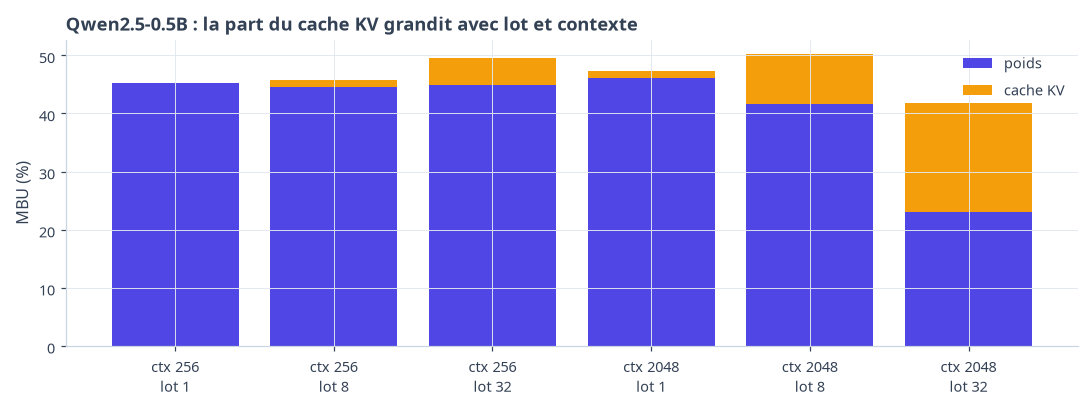

contexte,lot,pas (ms),MBU poids,MBU poids + KV,part du cache
256,1,5.7,45%,45%,0%
256,8,5.8,45%,46%,2%
256,32,5.7,45%,50%,9%
2048,1,5.6,46%,47%,2%
2048,8,6.2,42%,50%,17%
2048,32,11.2,23%,42%,45%


In [5]:
tok, model = inf.retry_oom(llm.load, llm.SMALL)
cfg05 = KNOWN_CONFIGS["Qwen2.5-0.5B"]
N05 = llm.count_params(model)


def mbu_lab():
    rows = []
    for ctx in [256, 2048]:
        for B in [1, 8, 32]:
            t = inf.decode_step_time(model, batch=B, context=ctx, steps=12)["median"]
            kv = kv_cache_bytes(cfg05, ctx, batch=B)
            rows.append({"contexte": ctx, "lot": B, "pas (ms)": t * 1e3,
                         "MBU poids": N05 * 2 / t / RTX["bw"], "MBU poids + KV": (N05 * 2 + kv) / t / RTX["bw"],
                         "part du cache": kv / (N05 * 2 + kv)})
    return pd.DataFrame(rows)


lab = inf.retry_oom(mbu_lab)
fig, ax = plt.subplots(figsize=(10, 3.8))
lbl = [f"ctx {c}\nlot {b}" for c, b in zip(lab["contexte"], lab["lot"])]
ax.bar(lbl, lab["MBU poids"] * 100, color=INDIGO, label="poids")
ax.bar(lbl, (lab["MBU poids + KV"] - lab["MBU poids"]) * 100, bottom=lab["MBU poids"] * 100, color=AMBER, label="cache KV")
ax.set_ylabel("MBU (%)"); ax.set_title("Qwen2.5-0.5B : la part du cache KV grandit avec lot et contexte"); ax.legend()
plt.tight_layout(); plt.show()
lab.style.format({"pas (ms)": "{:.1f}", "MBU poids": "{:.0%}", "MBU poids + KV": "{:.0%}", "part du cache": "{:.0%}"}).hide(axis="index")

Le modèle a GQA (2 têtes KV seulement) : son cache est petit (12 ko par token), et pour un
lot de 1 il reste négligeable devant le gigaoctet de poids. Mais à 32 séquences de 2048
tokens, le cache représente une fraction notable des octets lus à chaque pas : ignorer le
cache dans la MBU sous-estime alors l'utilisation réelle de la bande passante.

> **À retenir.** Pour un lot de 1, MBU $\approx N b \times$ tokens/s $/ \beta$ ; pour de
> gros lots ou de longs contextes, ajoutez la lecture des caches KV. La MFU du decode est
> minuscule tant que le lot est petit.

## Exercice 9.3 : Percentiles, SLO et goodput selon la charge

**Énoncé.** On sert Qwen2.5-0.5B avec le modèle de coût du cours 4 (pas de decode
$a_0 + a_1 b$, prefill $p_0 + p_1 n$, mesurés) et un batching continu (lots de 32 au plus).
Le SLO est : TTFT $\le$ 300 ms **et** TPOT $\le$ 15 ms.

1. Pour des taux d'arrivée de 5 à 300 requêtes/s, simuler 500 requêtes et tracer le débit,
   le goodput et les p50 / p99 du TTFT.
2. Quelle charge maximale garantit qu'au moins 90 % des requêtes respectent le SLO ?
3. Pourquoi le p99 se dégrade-t-il bien avant le p50 ?

**Rappels.** Goodput = requêtes par seconde qui respectent le SLO (section *Throughput and
goodput*) ; batching continu (cours 4, section 3). On réutilise
`inf.simulate_batching` avec un `StepCost` calibré sur nos mesures.

**Solution.** On mesure d'abord le coût d'un pas (comme au cours 4), puis on simule.

modèle de coût : decode 5.6 + 0.005 b ms ; prefill 3.0 + 23.7 µs/token


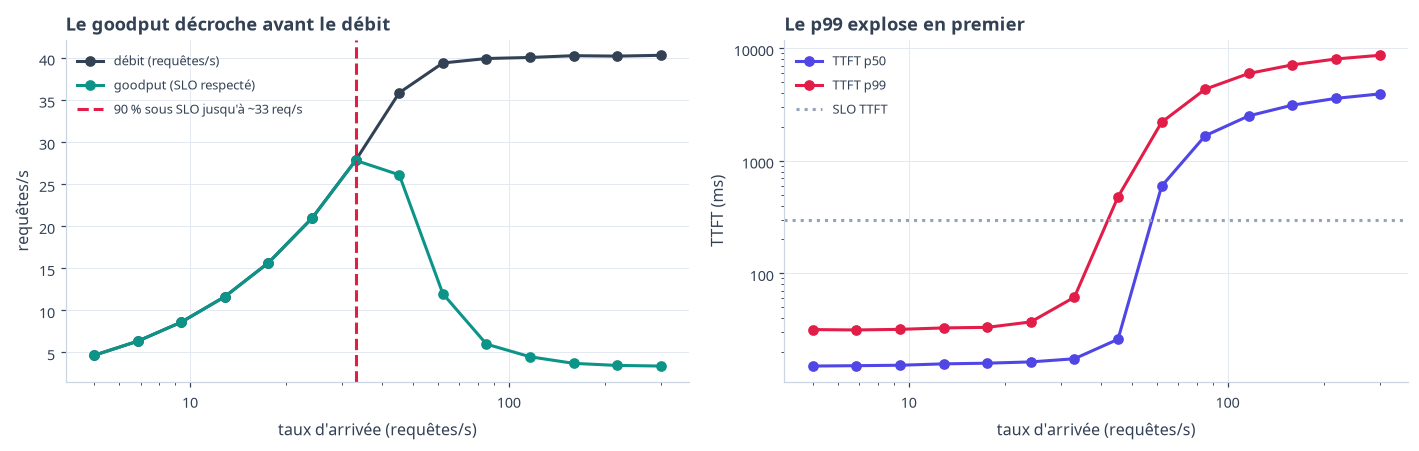

In [6]:
def calib():
    d = [(b, inf.decode_step_time(model, batch=b, context=256, steps=12)["median"]) for b in [1, 8, 32]]
    p = [(n, inf.prefill_time(model, n, repeats=4)["median"]) for n in [128, 512, 1024]]
    return np.array(d), np.array(p)


dd, pp = inf.retry_oom(calib)
a1, a0 = np.polyfit(dd[:, 0], dd[:, 1], 1)
p1, p0 = np.polyfit(pp[:, 0], pp[:, 1], 1)
cost = inf.StepCost(max(a0, 1e-3), max(a1, 1e-6), max(p0, 1e-3), max(p1, 1e-7))
print(f"modèle de coût : decode {cost.dec0 * 1e3:.1f} + {cost.dec1 * 1e3:.3f} b ms ;"
      f" prefill {cost.pre0 * 1e3:.1f} + {cost.pre1 * 1e6:.1f} µs/token")
slo_ttft, slo_tpot = 0.3, 0.015
rows = []
for lam in np.geomspace(5, 300, 14):
    w = inf.make_workload(500, rate=lam, seed=3)
    r = inf.simulate_batching(w, "continuous", max_batch=32, cost=cost)
    dur = r["fin"].max() - r["arrivee"].min()
    thr, good = inf.goodput(r["ttft"], r["tpot"], dur, slo_ttft, slo_tpot)
    rows.append(dict(taux=lam, débit=thr, goodput=good, frac_ok=good / thr,
                     ttft_p50=r["ttft"].median(), ttft_p99=r["ttft"].quantile(0.99), tpot_p50=r["tpot"].median()))
g93 = pd.DataFrame(rows)
ok = g93[g93["frac_ok"] >= 0.9]
lam_max = ok["taux"].max() if len(ok) else float("nan")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
ax.plot(g93["taux"], g93["débit"], "o-", color=SLATE, label="débit (requêtes/s)")
ax.plot(g93["taux"], g93["goodput"], "o-", color=TEAL, label="goodput (SLO respecté)")
ax.axvline(lam_max, color=ROSE, ls="--", label=f"90 % sous SLO jusqu'à ~{lam_max:.0f} req/s")
ax.set_xscale("log"); plain_log_axis(ax, "x"); ax.set_xlabel("taux d'arrivée (requêtes/s)")
ax.set_ylabel("requêtes/s"); ax.set_title("Le goodput décroche avant le débit"); ax.legend(fontsize=8.5)
ax = axes[1]
ax.plot(g93["taux"], g93["ttft_p50"] * 1e3, "o-", color=INDIGO, label="TTFT p50")
ax.plot(g93["taux"], g93["ttft_p99"] * 1e3, "o-", color=ROSE, label="TTFT p99")
ax.axhline(slo_ttft * 1e3, color=GRAY, ls=":", label="SLO TTFT")
ax.set_xscale("log"); ax.set_yscale("log"); plain_log_axis(ax, "x"); plain_log_axis(ax, "y")
ax.set_xlabel("taux d'arrivée (requêtes/s)"); ax.set_ylabel("TTFT (ms)"); ax.legend(fontsize=8.5)
ax.set_title("Le p99 explose en premier")
plt.tight_layout(); plt.show()

**Lecture.** (1) Tant que la charge est faible, débit et goodput coïncident ; à l'approche
de la saturation, le débit continue de croître (le serveur travaille à plein) alors que le
goodput décroche, puis s'effondre. (2) La charge maximale sous la contrainte « 90 % dans le
SLO » est indiquée par la ligne rouge : c'est elle, et non le débit maximal, qui sert au
dimensionnement. (3) Le p99 dépend des **pires** moments : une rafale d'arrivées remplit le
lot (32 places) et les requêtes suivantes attendent dans la file. Ces rafales existent même
à charge moyenne modérée (arrivées de Poisson), alors que le p50 ne voit que le cas typique.

> **À retenir.** Dimensionnez sur le goodput à un percentile élevé : un service à 80 % de
> son débit maximal peut déjà violer son SLO pour une part importante des requêtes.

## Exercice 9.4 : Coût par million de tokens, auto-hébergement contre API

**Énoncé.** On envisage d'héberger Llama 3-8B (bf16) sur un H100 loué 2,50 \$/h.

1. Borne de débit en decode (tokens de sortie par seconde) pour des lots de 1, 16 et 64,
   en supposant une MBU réaliste de 60 % et des contextes de 2 000 tokens (cache KV
   compris).
2. Coût par million de tokens de sortie correspondant.
3. Une API facture 0,20 \$ par million de tokens de sortie pour ce modèle. À partir de quel
   taux d'utilisation de la machine (fraction du temps où elle sert à pleine charge, lot de
   64) l'auto-hébergement devient-il moins cher ?

**Rappels.** Un pas de decode lit $Nb + B \cdot \text{KV}(S)$ octets et produit $B$ tokens
(cours 1) ; coût par million $= c / (3600\,D) \times 10^6$ (section *Throughput and
goodput*). Une machine louée se paie qu'elle travaille ou non.

**Solution.** Llama 3-8B : $N \approx 8{,}0 \cdot 10^9$, poids 16 Go ; GQA à 8 têtes KV de
dimension 128 sur 32 couches : $2 \cdot 32 \cdot 8 \cdot 128 \cdot 2 = 131$ ko par token, soit
0,27 Go pour 2 000 tokens. Pour $B = 64$ : $16 + 64 \times 0{,}27 \approx 33$ Go lus par
pas, $0{,}6 \times 3{,}35$ To/s effectifs : environ 61 pas/s, soit $\approx 3\,900$
tokens/s. Coût : $2{,}5 / (3600 \times 3\,900) \times 10^6 \approx 0{,}18$ \$ par million.
Pour battre 0,20 \$, il faut que la machine soit pleinement utilisée au moins
$0{,}18 / 0{,}20 \approx 90\,\%$ du temps : l'auto-hébergement n'est rentable qu'avec un
trafic soutenu et régulier. $\blacksquare$

cache KV par séquence de 2000 tokens : 0.26 Go ; utilisation minimale pour battre l'API : 89%


lot,débit (tokens/s),coût ($/M tokens)
1,123,5.639
16,"1,588",0.437
64,"3,917",0.177


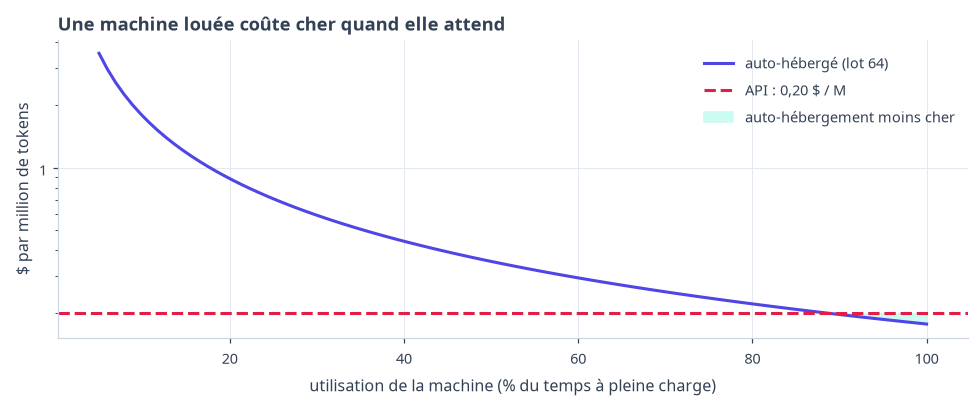

In [7]:
cfg8 = KNOWN_CONFIGS["Llama 3-8B"]
N8 = count_params_config(cfg8)
kv2k = kv_cache_bytes(cfg8, 2000)
rows = []
for B in [1, 16, 64]:
    D = inf.decode_tokens_per_s_bound(N8, 0.6 * H100["bw"], 2, batch=B, kv_bytes_per_seq=kv2k)
    rows.append({"lot": B, "débit (tokens/s)": D, "coût ($/M tokens)": inf.cost_per_million_tokens(2.5, D)})
c94 = pd.DataFrame(rows)
c64 = c94["coût ($/M tokens)"].iloc[-1]
print(f"cache KV par séquence de 2000 tokens : {kv2k / 1e9:.2f} Go ;"
      f" utilisation minimale pour battre l'API : {c64 / 0.20:.0%}")
display(c94.style.format({"débit (tokens/s)": "{:,.0f}", "coût ($/M tokens)": "{:.3f}"}).hide(axis="index"))

u = np.linspace(0.05, 1, 100)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(u * 100, c64 / u, color=INDIGO, label="auto-hébergé (lot 64)")
ax.axhline(0.20, color=ROSE, ls="--", label="API : 0,20 \\$ / M")
ax.fill_between(u * 100, c64 / u, 0.20, where=c64 / u < 0.20, color=LIGHT[TEAL], label="auto-hébergement moins cher")
ax.set_yscale("log"); plain_log_axis(ax, "y")
ax.set_xlabel("utilisation de la machine (% du temps à pleine charge)"); ax.set_ylabel("\\$ par million de tokens")
ax.set_title("Une machine louée coûte cher quand elle attend"); ax.legend()
plt.tight_layout(); plt.show()

> **À retenir.** Le coût par token d'une machine dépend surtout de la taille du lot et de
> son taux d'occupation. Les fournisseurs d'API mutualisent le trafic de milliers de
> clients : il est difficile de les battre sans un trafic important et régulier.

## Exercice 9.5 : Dimensionner un service pour Llama 3-70B

**Énoncé.** Un service doit traiter 20 requêtes/s en moyenne, avec des prompts de 1 500
tokens et des réponses de 300 tokens. SLO : TPOT $\le$ 40 ms. Matériel : H100 SXM 80 Go,
modèle en bf16, parallélisme de tenseur sur 4 GPU par réplique (on néglige la
communication et on suppose une MBU de 60 %).

1. Combien de requêtes une réplique peut-elle traiter **simultanément** (mémoire) ?
2. Quel lot maximal respecte le TPOT de 40 ms ?
3. Combien de requêtes simultanées faut-il en moyenne (loi de Little), et combien de
   répliques (donc de GPU) ?

**Rappels.** Mémoire = poids + caches KV (cours 3) ; durée d'un pas de decode
$\approx (Nb + B\cdot\text{KV})/(\text{MBU}\cdot\beta)$ ; **loi de Little** : nombre moyen
de requêtes en cours $= \lambda \times$ durée moyenne d'une requête.

**Solution.**

1. Poids : $70{,}6 \cdot 10^9 \times 2 \approx 141$ Go. Une réplique a $4 \times 80 = 320$ Go ;
   en gardant 10 % de marge, il reste environ 147 Go pour les caches. Cache par requête
   (1 800 tokens, 80 couches, 8 têtes KV de dimension 128) :
   $2 \cdot 80 \cdot 8 \cdot 128 \cdot 2 \cdot 1800 \approx 0{,}59$ Go ; donc environ 249
   requêtes simultanées.
2. Un pas lit $141 + 0{,}59 B$ Go à $0{,}6 \times 4 \times 3{,}35 = 8{,}04$ To/s ; il doit
   durer moins de 40 ms : $141 + 0{,}59B \le 322$, soit $B \le 306$. La mémoire est donc la
   contrainte la plus forte (249).
3. Durée d'une requête : TTFT (petit) $+ 300 \times$ TPOT. Au lot maximal, TPOT
   $\approx (141 + 0{,}59 \cdot 249)/8\,040 \approx 36$ ms, soit environ 11 s par requête ;
   loi de Little : $20 \times 11 \approx 220$ requêtes simultanées en moyenne. Une
   réplique suffit à peine en moyenne ; avec les rafales, on en prévoit **deux**, soit 8 GPU.
   $\blacksquare$

poids 141 Go ; cache/requête 0.59 Go ; lot max mémoire 249, SLO 306
TPOT au lot max 36 ms ; durée d'une requête 10.7 s ; requêtes simultanées (Little) 215 -> répliques nécessaires en moyenne : 0.86


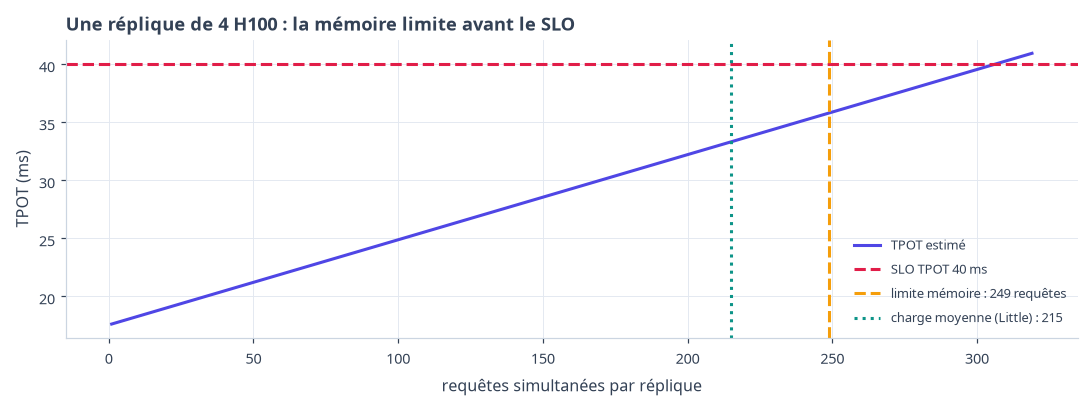

In [8]:
cfg70 = KNOWN_CONFIGS["Llama 3-70B"]
W70 = count_params_config(cfg70) * 2
kv_req = kv_cache_bytes(cfg70, 1800)
mem = 4 * 80e9 * 0.9
B_mem = int((mem - W70) // kv_req)
bw_eff = 0.6 * 4 * H100["bw"]
B_slo = int((0.040 * bw_eff - W70) // kv_req)
B_max = min(B_mem, B_slo)
tpot = (W70 + B_max * kv_req) / bw_eff
duree = 300 * tpot
L_little = 20 * duree
print(f"poids {W70 / 1e9:.0f} Go ; cache/requête {kv_req / 1e9:.2f} Go ; lot max mémoire {B_mem}, SLO {B_slo}")
print(f"TPOT au lot max {tpot * 1e3:.0f} ms ; durée d'une requête {duree:.1f} s ; requêtes simultanées (Little) {L_little:.0f}"
      f" -> répliques nécessaires en moyenne : {L_little / B_max:.2f}")

Bs = np.arange(1, 320)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(Bs, (W70 + Bs * kv_req) / bw_eff * 1e3, color=INDIGO, label="TPOT estimé")
ax.axhline(40, color=ROSE, ls="--", label="SLO TPOT 40 ms")
ax.axvline(B_mem, color=AMBER, ls="--", label=f"limite mémoire : {B_mem} requêtes")
ax.axvline(L_little, color=TEAL, ls=":", label=f"charge moyenne (Little) : {L_little:.0f}")
ax.set_xlabel("requêtes simultanées par réplique"); ax.set_ylabel("TPOT (ms)")
ax.set_title("Une réplique de 4 H100 : la mémoire limite avant le SLO"); ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

> **À retenir.** Dimensionner = trois contraintes : mémoire (poids + caches), latence (TPOT
> en fonction du lot) et charge (loi de Little). La plus serrée fixe le lot, la charge fixe
> le nombre de répliques, et on garde de la marge pour les rafales.

## Exercice 9.6 : Quantification par groupes, symétrique ou asymétrique

**Énoncé.**

1. Implémenter une quantification **asymétrique** (min-max, avec point zéro) par groupes de
   $g$ poids : $s = (\max - \min)/(2^b - 1)$, $z = \mathrm{round}(-\min/s)$,
   $q = \mathrm{clip}(\mathrm{round}(w/s) + z)$.
2. Comparer son erreur à la version symétrique (absmax) sur les vraies matrices de
   Qwen2.5-0.5B, en 4 et 3 bits, pour $g \in \{32, 128\}$. Expliquer la différence.
3. Pour un modèle de 7 milliards de paramètres sur un GPU à 1 To/s, quelle vitesse de
   decode maximale (lot de 1) en bf16, int8, int4 avec groupes de 128 (échelle et point
   zéro en 16 bits) ?

**Rappels.** Quantification absmax et granularité (cours 2, section 2) ; bits effectifs
$b + (\text{bits des paramètres du groupe})/g$ ; vitesse de decode bornée par
$\beta / (N \times \text{octets par poids})$ (cours 1).

**Solution.** Le symétrique centre la grille sur 0 et « gaspille » une partie des niveaux
si la distribution d'un groupe n'est pas symétrique (par exemple un groupe dont toutes les
valeurs sont positives). L'asymétrique cale la grille sur $[\min, \max]$ : ses $2^b$ niveaux
couvrent exactement l'étendue, au prix d'un point zéro par groupe. Avec peu de bits, chaque
niveau compte, et l'asymétrique gagne ; avec de petits groupes, l'écart diminue.

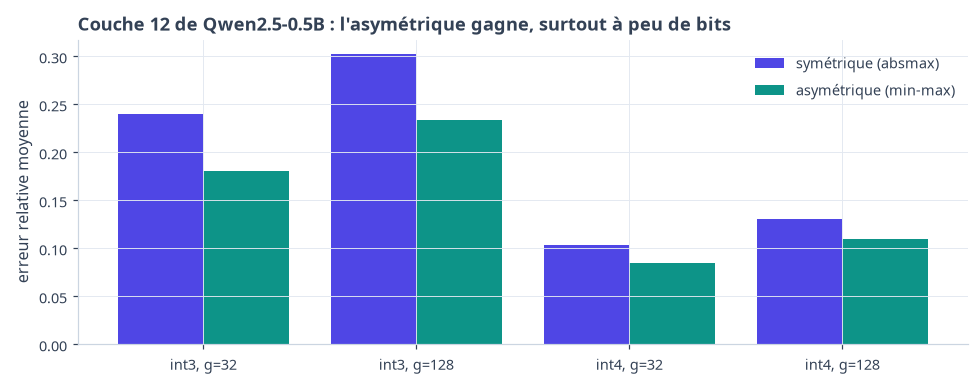

In [9]:
def quantize_asym(x, bits, group_size):
    g = np.asarray(x, dtype=np.float64).reshape(-1, group_size)
    lo, hi = g.min(1, keepdims=True), g.max(1, keepdims=True)
    s = (hi - lo) / (2 ** bits - 1)
    s[s == 0] = 1
    z = np.round(-lo / s)
    q = np.clip(np.round(g / s) + z, 0, 2 ** bits - 1)
    return ((q - z) * s).reshape(np.shape(x))


mats = {n: m.weight.detach().float().cpu().numpy() for n, m in model.named_modules()
        if isinstance(m, torch.nn.Linear) and ".layers.12." in n}
rows = []
for name, Wm in mats.items():
    for bits in [4, 3]:
        for gs in [32, 128]:
            e_sym = np.linalg.norm(inf.quantize_symmetric(Wm, bits, group_size=gs)[0] - Wm) / np.linalg.norm(Wm)
            e_asym = np.linalg.norm(quantize_asym(Wm, bits, gs) - Wm) / np.linalg.norm(Wm)
            rows.append(dict(matrice=name.split(".")[-1], bits=bits, groupe=gs, symétrique=e_sym, asymétrique=e_asym))
q96 = pd.DataFrame(rows)
summary = q96.groupby(["bits", "groupe"])[["symétrique", "asymétrique"]].mean()
fig, ax = plt.subplots(figsize=(9, 3.6))
lbls = [f"int{b}, g={g}" for b, g in summary.index]
xx = np.arange(len(summary))
ax.bar(xx - 0.2, summary["symétrique"], 0.4, color=INDIGO, label="symétrique (absmax)")
ax.bar(xx + 0.2, summary["asymétrique"], 0.4, color=TEAL, label="asymétrique (min-max)")
ax.set_xticks(xx, lbls); ax.set_ylabel("erreur relative moyenne"); ax.legend()
ax.set_title("Couche 12 de Qwen2.5-0.5B : l'asymétrique gagne, surtout à peu de bits")
plt.tight_layout(); plt.show()
summary.style.format("{:.4f}")

In [10]:
N7 = 7e9
for name, bpw in [("bf16", 16), ("int8 (par canal)", 8), ("int4, g=128, échelle + zéro 16 bits", 4 + 32 / 128)]:
    print(f"{name:38s}: {bpw:5.2f} bits/poids -> {N7 * bpw / 8 / 1e9:5.2f} Go -> "
          f"{inf.decode_tokens_per_s_bound(N7, 1e12, bpw / 8):5.0f} tokens/s max")

bf16                                  : 16.00 bits/poids -> 14.00 Go ->    71 tokens/s max
int8 (par canal)                      :  8.00 bits/poids ->  7.00 Go ->   143 tokens/s max
int4, g=128, échelle + zéro 16 bits   :  4.25 bits/poids ->  3.72 Go ->   269 tokens/s max


Le passage en int4 par groupes multiplie la borne de vitesse par environ 3,8 (et non 4 :
0,25 bit par poids pour l'échelle et le point zéro). Comme l'a montré le cours 2, cette
borne n'est atteinte qu'avec un noyau qui déquantifie à la volée sans surcoût.

> **À retenir.** Asymétrique = une grille calée sur l'étendue réelle de chaque groupe :
> meilleure à bas débit, pour un paramètre de plus par groupe. Le débit maximal du decode
> est inversement proportionnel aux bits effectifs par poids.

In [11]:
llm.free_gpu()
del model